# 02 — iMAGE: fine-tune Restormer, DnCNN and NAFNet

**Run cells from top to bottom.** This notebook uses the verified **SIDD (3,500) + PolyU (1,500)** paired-image manifest. Start with a 5-step DnCNN smoke test, then switch to full fine-tuning. Pretrained weights are fetched online and cached on first use. **Do not evaluate or tune against the test split here.**


## Step 1 — Project and GPU setup


In [1]:
from pathlib import Path
import sys, os, torch, pandas as pd
ROOT = Path.cwd().resolve()
if not (ROOT / 'app').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'app').is_dir():
    raise FileNotFoundError('Open CCS250_CompVis_Final as your VS Code folder')
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
os.chdir(ROOT)
from app.experiments import dataset_counts, setup_device, get_network, fine_tune
from app.data import DenoiseDataset
from app.online import pretrained_path, architecture_path
DEVICE=setup_device()
assert DEVICE.type=='cuda', 'CUDA GPU not available; verify your PyTorch installation'
print('Project:',ROOT)
print('PyTorch:',torch.__version__,'GPU:',torch.cuda.get_device_name(0))
print('Dataset:',dataset_counts(ROOT/'data'/'splits.csv'))


Project: C:\Users\rmclo\OneDrive\Documents\GitHub\CCS250_CompVis_Final
PyTorch: 2.11.0+cu128 GPU: NVIDIA GeForce RTX 4070
Dataset: {'train': 4000, 'val': 500, 'test': 500}


c:\Users\rmclo\OneDrive\Documents\GitHub\CCS250_CompVis_Final\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Step 2 — Confirm shared paired-image loader


In [2]:
manifest = ROOT/'data'/'splits.csv'
train_ds = DenoiseDataset(manifest,'train',patch=128)
val_ds = DenoiseDataset(manifest,'val',patch=128)
noisy,clean = train_ds[0]
assert len(train_ds)==4000 and len(val_ds)==500
assert noisy.shape==clean.shape==(3,128,128)
assert torch.isfinite(noisy).all() and torch.isfinite(clean).all()
print('Train:',len(train_ds),'Validation:',len(val_ds),'Pair shape:',tuple(noisy.shape))
print('Data loader: PASSED')


Train: 4000 Validation: 500 Pair shape: (3, 128, 128)
Data loader: PASSED


## Step 3 — Choose model and test/full run

Leave `RUN_MODE="smoke"` for the first run. After it passes, change to `"full"` and rerun Steps 3–6. Re-run Steps 3–6 for each of `dncnn`, `nafnet`, `restormer`.


In [15]:
MODEL = 'restormer'  # dncnn, nafnet, restormer
RUN_MODE = 'full'  # smoke or full
assert MODEL in ('dncnn','nafnet','restormer')
assert RUN_MODE in ('smoke','full')
PATCH=128
BATCH_SIZE=2 if MODEL=='dncnn' else 1
EPOCHS=1 if RUN_MODE=='smoke' else 5
MAX_TRAIN_STEPS=5 if RUN_MODE=='smoke' else 0
VALIDATION_LIMIT=10 if RUN_MODE=='smoke' else 500
LEARNING_RATE=1e-5
SEED=42
SIGMA=25 # ignored for paired images
print('Model:',MODEL,'Run mode:',RUN_MODE,'Epochs:',EPOCHS,
      'Batch size:',BATCH_SIZE,'Max train steps:',MAX_TRAIN_STEPS,
      'Validation samples:',VALIDATION_LIMIT)


Model: restormer Run mode: full Epochs: 5 Batch size: 1 Max train steps: 0 Validation samples: 500


## Step 4 — Fetch pretrained weights and verify forward pass

This step may download a checkpoint from official or configured online repositories on first use. Third-party source is imported for Restormer/NAFNet.


In [16]:
if MODEL in ('restormer','nafnet'):
    print('Architecture:',architecture_path(MODEL))
checkpoint=pretrained_path(MODEL)
print('Pretrained checkpoint:',checkpoint)
model,source=get_network(MODEL,device=DEVICE,checkpoint=checkpoint)
model.eval()
with torch.inference_mode():
    test_input=noisy.unsqueeze(0).to(DEVICE)
    pred=model(test_input)
assert pred.shape==test_input.shape
assert torch.isfinite(pred).all()
print('Forward test: PASSED',tuple(pred.shape),pred.device)
del model, pred, test_input
if DEVICE.type=='cuda': torch.cuda.empty_cache()


Architecture: C:\Users\rmclo\OneDrive\Documents\GitHub\CCS250_CompVis_Final\cache\upstream\restormer_arch.py
Pretrained checkpoint: C:\Users\rmclo\OneDrive\Documents\GitHub\CCS250_CompVis_Final\cache\pretrained\restormer.pth
Forward test: PASSED (1, 3, 128, 128) cuda:0


## Step 5 — Run fine-tuning

**Smoke mode writes** `weights/{model}_finetuned.pth` and a training log. Full mode overwrites these with the full run. Complete the smoke test before starting full training. All three models use the identical training and validation partitions.


In [17]:
history = fine_tune(
    MODEL, epochs=EPOCHS, batch_size=BATCH_SIZE, patch=PATCH,
    sigma=SIGMA, lr=LEARNING_RATE,
    validation_limit=VALIDATION_LIMIT, max_train_steps=MAX_TRAIN_STEPS,
    seed=SEED, checkpoint=checkpoint
)
print('Finished:',MODEL,RUN_MODE,'; checkpoint:',ROOT/'weights'/f'{MODEL}_finetuned.pth')


restormer: fine-tuning on cuda from restormer.pth; 4000 train, 500 validation


restormer epoch 1/5: 100%|██████████| 4000/4000 [08:48<00:00,  7.58it/s]


{'epoch': 1, 'train_l1': 0.009586557624978013, 'validation_psnr_db': 41.79643046951294, 'elapsed_min': 9.094}


restormer epoch 2/5: 100%|██████████| 4000/4000 [12:47<00:00,  5.21it/s]


{'epoch': 2, 'train_l1': 0.00808701879865839, 'validation_psnr_db': 42.257051223754885, 'elapsed_min': 22.187}


restormer epoch 3/5: 100%|██████████| 4000/4000 [08:46<00:00,  7.60it/s]


{'epoch': 3, 'train_l1': 0.007898127077671234, 'validation_psnr_db': 42.14935390472412, 'elapsed_min': 31.254}


restormer epoch 4/5: 100%|██████████| 4000/4000 [08:45<00:00,  7.61it/s]


{'epoch': 4, 'train_l1': 0.007732266777806217, 'validation_psnr_db': 42.37046933364868, 'elapsed_min': 40.313}


restormer epoch 5/5: 100%|██████████| 4000/4000 [08:45<00:00,  7.62it/s]


{'epoch': 5, 'train_l1': 0.007603743269981351, 'validation_psnr_db': 42.17626629257202, 'elapsed_min': 49.36}
Best: 42.370 dB; saved C:\Users\rmclo\OneDrive\Documents\GitHub\CCS250_CompVis_Final\weights\restormer_finetuned.pth. Training log: C:\Users\rmclo\OneDrive\Documents\GitHub\CCS250_CompVis_Final\results\restormer_training.csv
Finished: restormer full ; checkpoint: C:\Users\rmclo\OneDrive\Documents\GitHub\CCS250_CompVis_Final\weights\restormer_finetuned.pth


## Step 6 — Review and plot validation curve


,epoch,train_l1,validation_psnr_db,elapsed_min
0,1,0.009587,41.796430,9.094
1,2,0.008087,42.257051,22.187
2,3,0.007898,42.149354,31.254
3,4,0.007732,42.370469,40.313
4,5,0.007604,42.176266,49.360


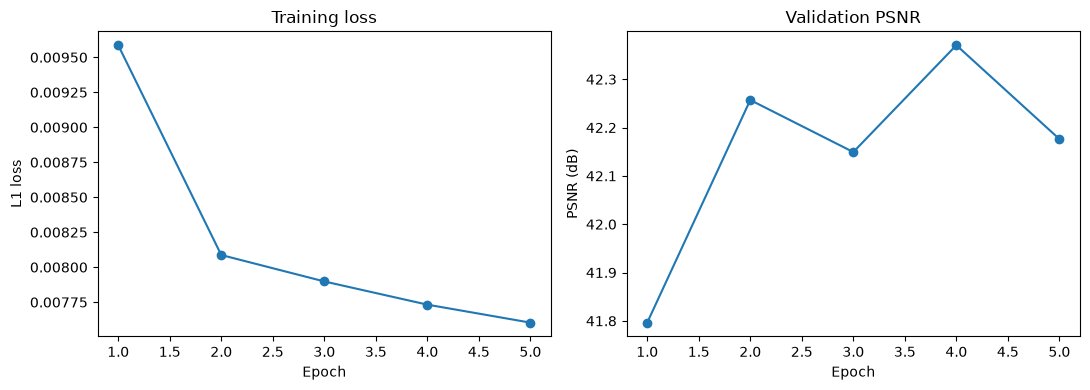

In [19]:
import matplotlib.pyplot as plt
log=ROOT/'results'/f'{MODEL}_training.csv'
results=pd.read_csv(log)
display(results)
fig, axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot(results.epoch,results.train_l1,marker='o')
axes[0].set(xlabel='Epoch',ylabel='L1 loss',title='Training loss')
axes[1].plot(results.epoch,results.validation_psnr_db,marker='o')
axes[1].set(xlabel='Epoch',ylabel='PSNR (dB)',title='Validation PSNR')
fig.tight_layout()
fig.savefig(ROOT/'results'/f'{MODEL}_training_curves.png',dpi=150)
plt.show()


## Next

After running full fine-tuning for all three models, use **03_evaluate_and_deploy.ipynb** with the untouched 500-image test set. Checkpoint download compatibility is not guaranteed by this notebook: if remote weights are unavailable, fix the source rather than silently substituting a random model.
